# Quantum Computation: Assignment 3

**Name:** ____________________

**Convention.** Qiskit orders qubits little-endian: a two-qubit basis ket is written $|q_1 q_0\rangle$, so qubit 0 is the
rightmost bit and the rightmost factor of every Kronecker product. A gate $G$ on qubit 0 is $I \otimes G$, and on qubit 1 it is $G \otimes I$.
The basis order is $|00\rangle, |01\rangle, |10\rangle, |11\rangle$, and every circuit starts in $|\psi_i\rangle = |00\rangle$.

Single-qubit matrices:
$I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\;
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\;
Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\;
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix},\;
H=\tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$

For $A=\begin{pmatrix}a&b\\c&d\end{pmatrix}$, the Kronecker product is
$A\otimes B=\begin{pmatrix}aB&bB\\cB&dB\end{pmatrix}$.
Successive gates multiply with the later gate on the left:
$(G_1\otimes I)(I\otimes G_0)=G_1\otimes G_0$.
The product rule $(A\otimes B)(|a\rangle\otimes|b\rangle)=A|a\rangle\otimes B|b\rangle$
explains each action below. Multiplication by a basis vector selects the corresponding column of $U$.

**Born rule:** if $|\psi_f\rangle=\sum_b a_b|b\rangle$, then
$P(b)=|\langle b|\psi_f\rangle|^2=|a_b|^2$ and $\sum_b P(b)=1$.
The measurement predictions and histograms use the default input $|00\rangle$;
actions on all four basis inputs are listed separately.
For $N$ independent shots, the expected count is $NP(b)$ with marginal standard deviation
$\sqrt{NP(b)(1-P(b))}$. All simulations here are ideal Aer simulations without a hardware noise model.
See [IBM's bit-ordering documentation](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit_aer import AerSimulator
from IPython.display import display, Markdown

SHOTS, SEED = 1024, 2026
BASIS = ["00", "01", "10", "11"]          # |q1 q0>
sim = AerSimulator(seed_simulator=SEED)

I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def analyze(qc, U_hand, label):
    # 1) the hand-derived Kronecker product must equal Qiskit's operator
    assert np.allclose(Operator(qc).data, U_hand), "hand-derived operator is wrong"
    display(Markdown(f"**{label}: U (matches `Operator(qc)`)**"))
    display(array_to_latex(U_hand, prefix="U = "))

    # 2) action on each basis ket
    rows = ["| input | U\\|input⟩ (amplitudes on 00, 01, 10, 11) |", "|---|---|"]
    for k, b in enumerate(BASIS):
        amps = ", ".join(f"{z.real:+.3f}{z.imag:+.3f}i" if abs(z.imag) > 1e-9 else f"{z.real:+.3f}"
                         for z in np.round(U_hand[:, k], 3))
        rows.append(f"| \\|{b}⟩ | ({amps}) |")
    display(Markdown("\n".join(rows)))

    # 3) predicted probabilities |<b|psi_f>|^2 for psi_i = |00>
    psi_f = U_hand @ Statevector.from_label("00").data
    assert np.allclose(psi_f, Statevector.from_label("00").evolve(qc).data)
    probs = {b: abs(psi_f[int(b, 2)]) ** 2 for b in BASIS}
    display(Markdown("**Predicted:** " + ", ".join(f"|⟨{b}|ψf⟩|² = {p:.2f}" for b, p in probs.items())))

    # 4) simulate and plot the histogram
    meas = qc.copy()
    meas.measure_all()
    counts = sim.run(transpile(meas, sim), shots=SHOTS).result().get_counts()
    counts = {b: counts.get(b, 0) for b in BASIS}
    print("Simulated counts:", counts)
    return plot_histogram(counts, title=f"{label}: {SHOTS} shots")

## Question 1(a)
`qc.x(0)` flips $q_0$ and `qc.x(1)` flips $q_1$, so
$$U = X_{q_1}\otimes X_{q_0} = X\otimes X = \begin{pmatrix}0\cdot X & 1\cdot X\\ 1\cdot X & 0\cdot X\end{pmatrix}
=\begin{pmatrix}0&0&0&1\\0&0&1&0\\0&1&0&0\\1&0&0&0\end{pmatrix}$$
**Action:** $|00\rangle\to|11\rangle,\ |01\rangle\to|10\rangle,\ |10\rangle\to|01\rangle,\ |11\rangle\to|00\rangle$.

**Prediction:** $|\psi_f\rangle = |11\rangle$, so $|\langle 11|\psi_f\rangle|^2 = 1$ and the other three probabilities are $0$.

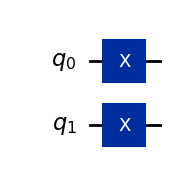

**Question 1(a): U (matches `Operator(qc)`)**

<IPython.core.display.Latex object>

| input | U\|input⟩ (amplitudes on 00, 01, 10, 11) |
|---|---|
| \|00⟩ | (+0.000, +0.000, +0.000, +1.000) |
| \|01⟩ | (+0.000, +0.000, +1.000, +0.000) |
| \|10⟩ | (+0.000, +1.000, +0.000, +0.000) |
| \|11⟩ | (+1.000, +0.000, +0.000, +0.000) |

**Predicted:** |⟨00|ψf⟩|² = 0.00, |⟨01|ψf⟩|² = 0.00, |⟨10|ψf⟩|² = 0.00, |⟨11|ψf⟩|² = 1.00

Simulated counts: {'00': 0, '01': 0, '10': 0, '11': 1024}


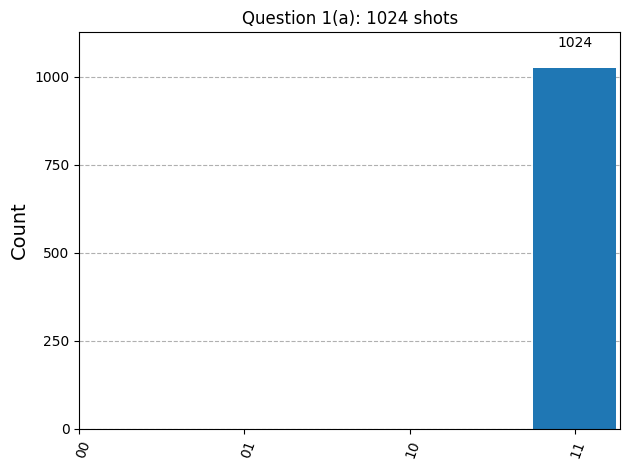

In [2]:
qc = QuantumCircuit(2)
qc.x(0)
qc.x(1)
display(qc.draw('mpl'))
analyze(qc, np.kron(X, X), 'Question 1(a)')

## Question 1(b)
Only $q_0$ gets a gate, and $q_1$ gets the identity:
$$U = I_{q_1}\otimes X_{q_0} = I\otimes X = \begin{pmatrix}X & 0\\ 0 & X\end{pmatrix}
=\begin{pmatrix}0&1&0&0\\1&0&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}$$
**Action:** $|00\rangle\to|01\rangle,\ |01\rangle\to|00\rangle,\ |10\rangle\to|11\rangle,\ |11\rangle\to|10\rangle$.

**Prediction:** $|\psi_f\rangle = |01\rangle$, so $|\langle 01|\psi_f\rangle|^2 = 1$ and the others are $0$. In Qiskit's bit order the result is `01`, not `10`.

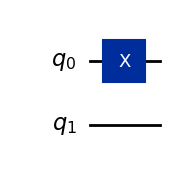

**Question 1(b): U (matches `Operator(qc)`)**

<IPython.core.display.Latex object>

| input | U\|input⟩ (amplitudes on 00, 01, 10, 11) |
|---|---|
| \|00⟩ | (+0.000, +1.000, +0.000, +0.000) |
| \|01⟩ | (+1.000, +0.000, +0.000, +0.000) |
| \|10⟩ | (+0.000, +0.000, +0.000, +1.000) |
| \|11⟩ | (+0.000, +0.000, +1.000, +0.000) |

**Predicted:** |⟨00|ψf⟩|² = 0.00, |⟨01|ψf⟩|² = 1.00, |⟨10|ψf⟩|² = 0.00, |⟨11|ψf⟩|² = 0.00

Simulated counts: {'00': 0, '01': 1024, '10': 0, '11': 0}


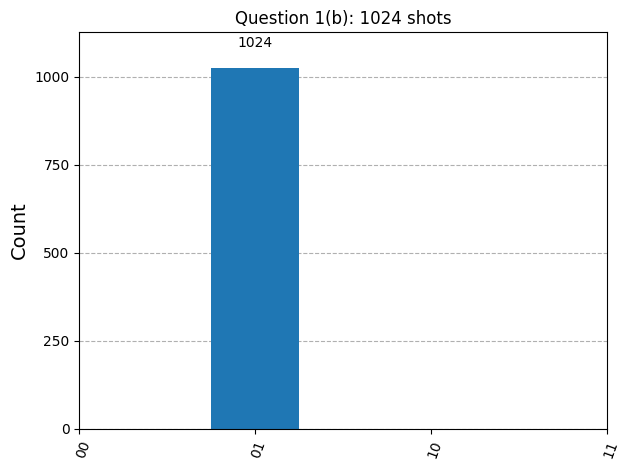

In [3]:
qc = QuantumCircuit(2)
qc.x(0)
display(qc.draw('mpl'))
analyze(qc, np.kron(I2, X), 'Question 1(b)')

## Question 1(c)
$$U = H\otimes H = \tfrac{1}{\sqrt2}\begin{pmatrix}H & H\\ H & -H\end{pmatrix}
=\tfrac12\begin{pmatrix}1&1&1&1\\1&-1&1&-1\\1&1&-1&-1\\1&-1&-1&1\end{pmatrix}$$
**Action:**
$|00\rangle\to\tfrac12(|00\rangle+|01\rangle+|10\rangle+|11\rangle)$,
$|01\rangle\to\tfrac12(|00\rangle-|01\rangle+|10\rangle-|11\rangle)$,
$|10\rangle\to\tfrac12(|00\rangle+|01\rangle-|10\rangle-|11\rangle)$,
$|11\rangle\to\tfrac12(|00\rangle-|01\rangle-|10\rangle+|11\rangle)$.

**Prediction:** each outcome has probability $\tfrac14$. With 1024 shots each bar should be about 256, give or take shot noise of about 14 counts.

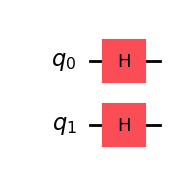

**Question 1(c): U (matches `Operator(qc)`)**

<IPython.core.display.Latex object>

| input | U\|input⟩ (amplitudes on 00, 01, 10, 11) |
|---|---|
| \|00⟩ | (+0.500, +0.500, +0.500, +0.500) |
| \|01⟩ | (+0.500, -0.500, +0.500, -0.500) |
| \|10⟩ | (+0.500, +0.500, -0.500, -0.500) |
| \|11⟩ | (+0.500, -0.500, -0.500, +0.500) |

**Predicted:** |⟨00|ψf⟩|² = 0.25, |⟨01|ψf⟩|² = 0.25, |⟨10|ψf⟩|² = 0.25, |⟨11|ψf⟩|² = 0.25

Simulated counts: {'00': 264, '01': 275, '10': 252, '11': 233}


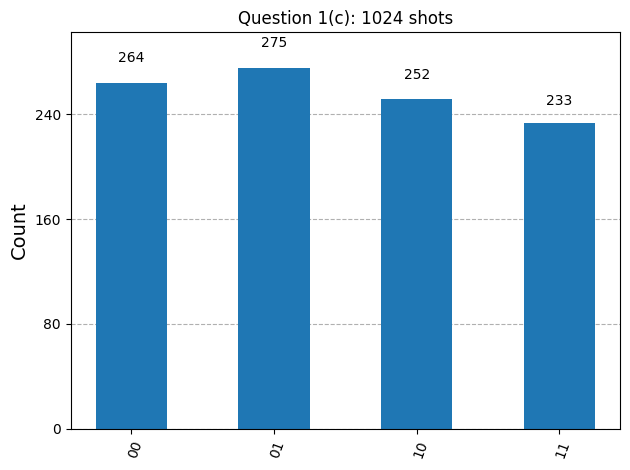

In [4]:
qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)
display(qc.draw('mpl'))
analyze(qc, np.kron(H, H), 'Question 1(c)')

## Question 1(d)
$Z$ acts on $q_0$ and $Y$ on $q_1$ (they act on different qubits, so their order does not matter):
$$U = Y_{q_1}\otimes Z_{q_0} = Y\otimes Z = \begin{pmatrix}0 & -iZ\\ iZ & 0\end{pmatrix}
=\begin{pmatrix}0&0&-i&0\\0&0&0&i\\i&0&0&0\\0&-i&0&0\end{pmatrix}$$
**Action:** $|00\rangle\to i|10\rangle,\ |01\rangle\to -i|11\rangle,\ |10\rangle\to -i|00\rangle,\ |11\rangle\to i|01\rangle$.

**Prediction:** $|\psi_f\rangle = i|10\rangle$, so $|\langle 10|\psi_f\rangle|^2 = |i|^2 = 1$ and the others are $0$. The global phase $i$ cannot be measured.

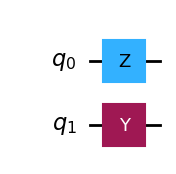

**Question 1(d): U (matches `Operator(qc)`)**

<IPython.core.display.Latex object>

| input | U\|input⟩ (amplitudes on 00, 01, 10, 11) |
|---|---|
| \|00⟩ | (+0.000, +0.000, +0.000+1.000i, +0.000) |
| \|01⟩ | (+0.000, -0.000, +0.000, -0.000-1.000i) |
| \|10⟩ | (+0.000-1.000i, +0.000, +0.000, +0.000) |
| \|11⟩ | (+0.000, +0.000+1.000i, +0.000, -0.000) |

**Predicted:** |⟨00|ψf⟩|² = 0.00, |⟨01|ψf⟩|² = 0.00, |⟨10|ψf⟩|² = 1.00, |⟨11|ψf⟩|² = 0.00

Simulated counts: {'00': 0, '01': 0, '10': 1024, '11': 0}


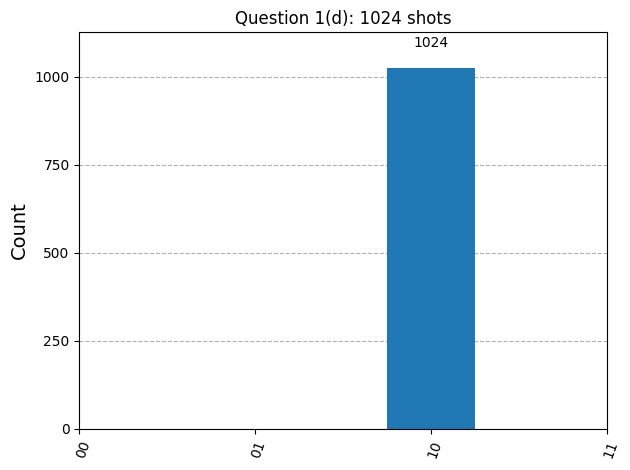

In [5]:
qc = QuantumCircuit(2)
qc.z(0)
qc.y(1)
display(qc.draw('mpl'))
analyze(qc, np.kron(Y, Z), 'Question 1(d)')

## Question 2

The filled dot on $q_0$ joined vertically to the X on $q_1$ is a **controlled-X (CNOT)**,
implemented as `qc.cx(0, 1)`: $q_0$ controls the flip of $q_1$.
The circuit is an initial barrier, $H$ on $q_0$, CNOT, another barrier,
then measurements $q_0\to c_0$ and $q_1\to c_1$. Barriers leave the state unchanged.

In the order $|q_1q_0\rangle$, CNOT sends $|q_1q_0\rangle$ to $|q_1\mathbin{\oplus}q_0,q_0\rangle$.
It fixes $|00\rangle$ and $|10\rangle$, and exchanges $|01\rangle$ with $|11\rangle$.
Thus
$$C=I\otimes|0\rangle\langle0|+X\otimes|1\rangle\langle1|
=\begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}.$$

Starting from the assigned input,
$$|00\rangle\xrightarrow{I\otimes H}\frac{|00\rangle+|01\rangle}{\sqrt2}
\xrightarrow{C}\frac{|00\rangle+|11\rangle}{\sqrt2}.$$
The $|00\rangle$ branch has control 0 and is unchanged; the $|01\rangle$ branch has control 1,
so its target flips and it becomes $|11\rangle$.

The total operator, with the first gate on the right, is
$$U=C(I\otimes H)=\frac1{\sqrt2}\begin{pmatrix}1&1&0&0\\0&0&1&-1\\0&0&1&1\\1&-1&0&0\end{pmatrix}.$$
Its first column gives the **state before measurement**:
$$|\psi_{out}\rangle=|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}
=\frac1{\sqrt2}(1,0,0,1)^T.$$

This is an entangled Bell state. Each qubit has reduced state $I/2$, and their measurement
results always agree. The Born rule gives $P(00)=P(11)=1/2$ and $P(01)=P(10)=0$.
At 1024 shots, each allowed outcome has expected count 512 and marginal standard deviation 16.

After ideal measurement, a single run has state $|00\rangle$ or $|11\rangle$.
Discarding the measurement record leaves the mixture
$\rho=\frac12|00\rangle\langle00|+\frac12|11\rangle\langle11|=\operatorname{diag}(1/2,0,0,1/2)$.
The histogram verifies computational-basis probabilities; a classical mixture can give the same histogram,
so the statevector verifies coherence in this ideal calculation.

<IPython.core.display.Latex object>

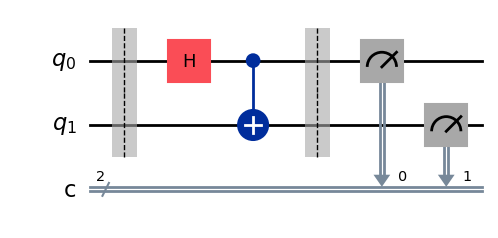

Simulated counts: {'00': 516, '01': 0, '10': 0, '11': 508}


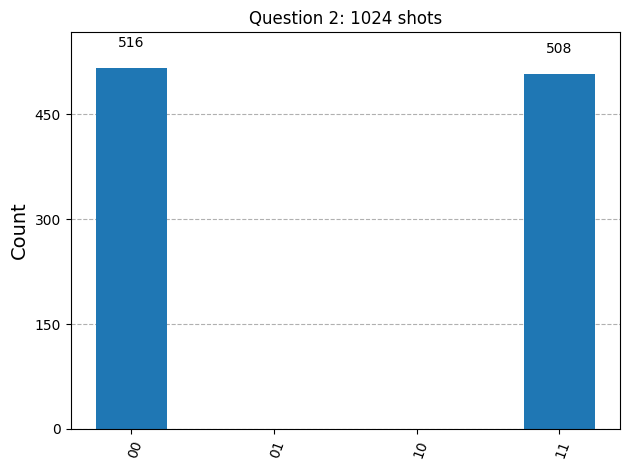

In [6]:
qc2 = QuantumCircuit(2, 2)
qc2.barrier()
qc2.h(0)
qc2.cx(0, 1)
qc2.barrier()

C_hand = np.array([[1, 0, 0, 0], [0, 0, 0, 1],
                   [0, 0, 1, 0], [0, 1, 0, 0]])
assert np.allclose(Operator(qc2).data, C_hand @ np.kron(I2, H))
psi_out = Statevector.from_label("00").evolve(qc2)
assert np.allclose(psi_out.data, np.array([1, 0, 0, 1]) / np.sqrt(2))
display(array_to_latex(psi_out.data, prefix=r"|\psi_{out}\rangle = "))

qc2.measure([0, 1], [0, 1])
display(qc2.draw("mpl"))
counts2 = sim.run(transpile(qc2, sim), shots=SHOTS).result().get_counts()
counts2 = {b: counts2.get(b, 0) for b in BASIS}
assert counts2["01"] == counts2["10"] == 0
print("Simulated counts:", counts2)
plot_histogram(counts2, title=f"Question 2: {SHOTS} shots")

## Question 3: How qubits are represented on an IBM quantum computer

IBM represents each physical qubit using a superconducting *transmon*: an electrical circuit with a Josephson junction connected in parallel with a capacitor [1]. The junction contains a thin insulating barrier between superconductors and supplies a nonlinear inductance. Together with the capacitance, it produces a quantum oscillator with unequal energy-level spacings. Its ground and first excited energy eigenstates define the computational states |0⟩ and |1⟩ [2, 3]. Within this two-level subspace, a pure state is |ψ⟩ = α|0⟩ + β|1⟩, with complex amplitudes satisfying |α|² + |β|² = 1; their relative phase also carries quantum information. The large capacitance reduces sensitivity to charge noise, while the remaining anharmonicity permits selective control [2]. IBM cools its processors in dilution refrigerators to temperatures of roughly 15–20 mK to reduce thermal excitation [4].

Shaped microwave pulses manipulate the amplitudes and relative phase to implement single-qubit gates, while interactions between coupled qubits implement entangling gates [1, 3]. A transmon has higher energy levels, so pulse calibration and shaping suppress unwanted population leakage outside |0⟩ and |1⟩; leakage is not automatically zero [3]. For dispersive readout, a transmon couples to a microwave resonator whose response depends on the qubit state. A probe signal is amplified and classified to return a classical 0 or 1 [1, 3]. Ideally, a computational-basis measurement of α|0⟩ + β|1⟩ returns 0 with probability |α|² and 1 with probability |β|². One such measurement does not reveal both complex amplitudes; repeated preparations and measurements estimate probabilities. Physical devices also experience relaxation, dephasing, control imperfections, and readout errors [3]. The histograms in this assignment instead use an ideal AerSimulator without a hardware noise model: their random variation comes from finite-shot sampling of the predicted probabilities.

### References

1. IBM Quantum Learning, “Running quantum circuits,” [IBM Quantum course](https://quantum.cloud.ibm.com/learning/en/courses/quantum-computing-in-practice/running-quantum-circuits) (accessed Oct. 9, 2026).
2. J. Koch *et al.*, “Charge-insensitive qubit design derived from the Cooper pair box,” *Phys. Rev. A* 76, 042319 (2007). [doi:10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319).
3. A. Blais, A. L. Grimsmo, S. M. Girvin, and A. Wallraff, “Circuit quantum electrodynamics,” *Rev. Mod. Phys.* 93, 025005 (2021). [doi:10.1103/RevModPhys.93.025005](https://doi.org/10.1103/RevModPhys.93.025005).
4. IBM Quantum, “Five years ago today, we put the first quantum computer on the cloud. Here’s how we did it,” May 4, 2021. [IBM Quantum blog](https://www.ibm.com/quantum/blog/quantum-five-years) (accessed Oct. 9, 2026).